# Forest Intrusion Detection — YOLOv8n

## Objectives
- Detect forest wildlife.
- Detect people entering restricted areas.
- Detect visible firearms and generate priority alerts.
- Track objects across video frames.
- Save detection results and evidence.

## Training strategy
- Model: YOLOv8n
- Initial epochs: 20
- Image size: 640 × 640
- Training: Google Colab GPU
- Classes: animal, person, firearm

Note: Results depend on dataset quality. Firearm alerts require human review.

In [1]:
import os
import sys

IN_COLAB = "google.colab" in sys.modules

print("Running in Google Colab:", IN_COLAB)

if IN_COLAB:
    import torch
    print("PyTorch:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
    else:
        print("No GPU assigned. Enable one in Runtime > Change runtime type.")
else:
    print("Local environment detected.")
    print("For training, use a Colab GPU if available.")

Running in Google Colab: False
Local environment detected.
For training, use a Colab GPU if available.


In [2]:
%pip install -q ultralytics pyyaml matplotlib pandas opencv-python-headless     

Note: you may need to restart the kernel to use updated packages.


In [1]:
import torch
import ultralytics

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Ultralytics:", ultralytics.__version__)

PyTorch: 2.14.1+cpu
CUDA available: False
Ultralytics: 8.4.183


In [2]:
from pathlib import Path
import os
import yaml
import random
import shutil
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from ultralytics import YOLO

SEED = 42
random.seed(SEED)

PROJECT_DIR = Path("/content/forest-intrusion")
DATASET_DIR = PROJECT_DIR / "datasets" / "raw"
RUNS_DIR = PROJECT_DIR / "runs"

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
RUNS_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATASET_DIR)

Project directory: \content\forest-intrusion
Dataset directory: \content\forest-intrusion\datasets\raw


In [4]:
from pathlib import Path

RAW_DIR = Path(
    r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion\datasets\raw"
)

if not RAW_DIR.exists():
    raise FileNotFoundError(f"Folder not found: {RAW_DIR}")

zip_files = sorted(RAW_DIR.rglob("*.zip"))

print(f"Found {len(zip_files)} ZIP files:\n")

for i, file in enumerate(zip_files, start=1):
    print(f"{i}. {file.relative_to(RAW_DIR)}")

Found 3 ZIP files:

1. ena24\ena24.zip
2. firearms\WeaponDataset.v11i.yolov8.zip
3. people\People Detection.v12i.yolov8.zip


In [6]:
from pathlib import Path
import zipfile

RAW_DIR = Path(
    r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion\datasets\raw"
)

EXTRACT_DIR = RAW_DIR.parent / "extracted"
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

zip_files = sorted(RAW_DIR.rglob("*.zip"))

if not zip_files:
    raise FileNotFoundError(f"No ZIP files found in {RAW_DIR}")

print(f"Found {len(zip_files)} ZIP files.")

for i, zip_path in enumerate(zip_files, start=1):
    destination = EXTRACT_DIR / zip_path.relative_to(RAW_DIR).parent / zip_path.stem
    destination.mkdir(parents=True, exist_ok=True)

    print(f"[{i}/{len(zip_files)}] Extracting: {zip_path.name}")

    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(destination)

print(f"\nExtraction complete. Files saved to:\n{EXTRACT_DIR}")

Found 3 ZIP files.
[1/3] Extracting: ena24.zip
[2/3] Extracting: WeaponDataset.v11i.yolov8.zip
[3/3] Extracting: People Detection.v12i.yolov8.zip

Extraction complete. Files saved to:
C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion\datasets\extracted


In [8]:
from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion"
)
RAW_DIR = PROJECT_DIR / "datasets" / "raw"
EXTRACT_DIR = PROJECT_DIR / "datasets" / "extracted"

print("Project exists:", PROJECT_DIR.exists())
print("Raw directory exists:", RAW_DIR.exists())
print("Extracted directory exists:", EXTRACT_DIR.exists())

print("\nExtracted folder structure:")
if EXTRACT_DIR.exists():
    for path in list(EXTRACT_DIR.rglob("*"))[:100]:
        level = len(path.relative_to(EXTRACT_DIR).parts)
        print("  " * (level - 1) + path.name)
else:
    print("Extracted directory not found.")

Project exists: True
Raw directory exists: True
Extracted directory exists: True

Extracted folder structure:
ena24
firearms
people
  ena24
  WeaponDataset.v11i.yolov8
  People Detection.v12i.yolov8
    data.yaml
    README.dataset.txt
    README.roboflow.txt
    test
    train
    valid
      images
      labels
      images
      labels
      images
      labels
        -1_-Av513706663-P1-_mp4-0_jpg.rf.1710b73d2d6b1b7a4d8727b28f215189.jpg
        -1_-Av513706663-P1-_mp4-13_jpg.rf.5d80f2efbc69e36538b631f8cc075379.jpg
        -1_-Av513706663-P1-_mp4-15_jpg.rf.fb34946a989957f58ee6ffab1f9703ae.jpg
        -1_-Av513706663-P1-_mp4-16_jpg.rf.8cddb30827a48fe98f9905fc95f64a57.jpg
        -1_-Av513706663-P1-_mp4-18_jpg.rf.5ca8ba50fcee4ec9755dabd53bd2fa7e.jpg
        -1_-Av513706663-P1-_mp4-19_jpg.rf.97354e8c9829dc8ba24c2384564978b0.jpg
        -1_-Av513706663-P1-_mp4-1_jpg.rf.791d1d796d2362defb28d03c01f3e55d.jpg
        -1_-Av513706663-P1-_mp4-21_jpg.rf.e2db07731bcb8cba9e8118578b00351e.jpg
   

In [11]:
from pathlib import Path
import cv2

PROJECT_DIR = Path(
    r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion"
)

DATASET_DIR = PROJECT_DIR / "datasets" / "extracted"

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Update these names/IDs to match your dataset's actual class mapping.
CLASS_NAMES = ["animal", "person", "firearm"]


def validate_split(split):
    image_dir = DATASET_DIR / "images" / split
    label_dir = DATASET_DIR / "labels" / split

    if not image_dir.is_dir() or not label_dir.is_dir():
        print(f"{split}: YOLO split not found; skipping.")
        return

    images = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    ]
    labels = {p.stem: p for p in label_dir.glob("*.txt")}

    missing = []
    invalid = []
    class_counts = {i: 0 for i in range(len(CLASS_NAMES))}

    for image_path in images:
        label_path = labels.get(image_path.stem)

        if label_path is None:
            missing.append(image_path.name)
            continue

        image = cv2.imread(str(image_path))
        if image is None:
            invalid.append((image_path.name, "Unreadable image"))
            continue

        try:
            for line_no, line in enumerate(
                label_path.read_text(encoding="utf-8").splitlines(),
                start=1
            ):
                parts = line.split()
                if not parts:
                    continue

                if len(parts) != 5:
                    invalid.append(
                        (label_path.name, f"Line {line_no}: expected 5 values")
                    )
                    continue

                try:
                    cls, x, y, w, h = map(float, parts)
                except ValueError:
                    invalid.append(
                        (label_path.name, f"Line {line_no}: non-numeric values")
                    )
                    continue

                if (
                    not cls.is_integer()
                    or int(cls) not in class_counts
                    or not all(0 <= v <= 1 for v in (x, y, w, h))
                    or w <= 0
                    or h <= 0
                ):
                    invalid.append(
                        (label_path.name, f"Line {line_no}: invalid class ID or box")
                    )
                    continue

                class_counts[int(cls)] += 1

        except Exception as exc:
            invalid.append((label_path.name, str(exc)))

    print(f"\n{split}: {len(images)} images")
    print("Images without label files:", len(missing))
    print("Invalid images/annotations:", len(invalid))
    print("Bounding-box counts:", {
        CLASS_NAMES[k]: v for k, v in class_counts.items()
    })

    if missing:
        print("Examples missing labels:", missing[:5])
    if invalid:
        print("Examples of invalid entries:", invalid[:5])


print("Dataset directory:", DATASET_DIR)
print("Directory exists:", DATASET_DIR.is_dir())

for split in ["train", "val", "test"]:
    validate_split(split)

Dataset directory: C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion\datasets\extracted
Directory exists: True
train: YOLO split not found; skipping.
val: YOLO split not found; skipping.
test: YOLO split not found; skipping.


In [12]:
from pathlib import Path

EXTRACT_DIR = Path(
    r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion\datasets\extracted"
)

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
ANNOTATION_EXTS = {".txt", ".json", ".xml", ".csv"}

for folder in sorted(p for p in EXTRACT_DIR.iterdir() if p.is_dir()):
    print(f"\n{'=' * 60}\nFOLDER: {folder.name}")

    images = []
    annotations = []
    configs = []

    for p in folder.rglob("*"):
        if not p.is_file():
            continue

        if p.suffix.lower() in IMAGE_EXTS:
            images.append(p)
        elif p.suffix.lower() in ANNOTATION_EXTS:
            annotations.append(p)

        if p.name.lower() in {"data.yaml", "data.yml", "dataset.yaml",
                              "_annotations.coco.json"}:
            configs.append(p)

    print("Images:", len(images))
    print("Annotation files:", len(annotations))
    print("Configuration files:", len(configs))

    print("Example images:")
    for p in images[:3]:
        print("  ", p.relative_to(EXTRACT_DIR))

    print("Example annotations:")
    for p in annotations[:3]:
        print("  ", p.relative_to(EXTRACT_DIR))

    print("Configuration files:")
    for p in configs[:5]:
        print("  ", p.relative_to(EXTRACT_DIR))


FOLDER: ena24
Images: 8789
Annotation files: 0
Configuration files: 0
Example images:
   ena24\ena24\1.jpg
   ena24\ena24\10.jpg
   ena24\ena24\100.jpg
Example annotations:
Configuration files:

FOLDER: firearms
Images: 24083
Annotation files: 24085
Configuration files: 1
Example images:
   firearms\WeaponDataset.v11i.yolov8\valid\images\05100d70-BOCW-Ballistic-Knife-001_jpg.rf.0046b31c33c2fa0e6b69b5f02e3dc955.jpg
   firearms\WeaponDataset.v11i.yolov8\valid\images\05cee6e5f0497086_jpg.rf.875c84ddaa41080e6b20fbda41173d89.jpg
   firearms\WeaponDataset.v11i.yolov8\valid\images\095b6f4b-281_jpeg_jpg.rf.b3e6d1ffcfbb479d5e6ab8e156474b46.jpg
Example annotations:
   firearms\WeaponDataset.v11i.yolov8\README.dataset.txt
   firearms\WeaponDataset.v11i.yolov8\README.roboflow.txt
   firearms\WeaponDataset.v11i.yolov8\valid\labels\05100d70-BOCW-Ballistic-Knife-001_jpg.rf.0046b31c33c2fa0e6b69b5f02e3dc955.txt
Configuration files:
   firearms\WeaponDataset.v11i.yolov8\data.yaml

FOLDER: people
Images

In [13]:
from pathlib import Path
import yaml

PROJECT_DIR = Path(
    r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion"
)
EXTRACT_DIR = PROJECT_DIR / "datasets" / "extracted"

for yaml_file in EXTRACT_DIR.rglob("data.yaml"):
    print(f"\n{'=' * 60}")
    print("CONFIG:", yaml_file.relative_to(EXTRACT_DIR))

    with open(yaml_file, "r", encoding="utf-8") as f:
        config = yaml.safe_load(f)

    print("Classes:", config.get("names"))
    print("Declared class count:", config.get("nc"))
    print("Train path:", config.get("train"))
    print("Validation path:", config.get("val"))
    print("Test path:", config.get("test"))

print("\n--- ENA24 wildlife dataset ---")
ena_dir = EXTRACT_DIR / "ena24"

for p in list(ena_dir.rglob("*"))[:30]:
    if p.is_file():
        print(p.relative_to(EXTRACT_DIR))


CONFIG: people\People Detection.v12i.yolov8\data.yaml
Classes: ['0', '1', '2', 'Bicycle', 'Bike', 'Car', 'Cyclist', 'Pedestrian', 'Pedestrians', 'Persona', 'Pessoa', 'Signboard', 'Stopper', 'aeroplane', 'bag', 'berdiri', 'bicycle', 'bird', 'boat', 'bottle', 'bus', 'car', 'cat', 'chair', 'cow', 'cyclist', 'dianzhuan', 'diningtable', 'dog', 'face', 'forklift', 'handbag', 'head', 'helmet', 'high', 'horse', 'jatuh', 'laptop', 'low', 'medium', 'motorbike', 'people', 'person', 'persons', 'pottedplant', 'refrigerator', 'sheep', 'sofa', 'teddy bear', 'train', 'tv', 'tvmonitor', 'vase']
Declared class count: 53
Train path: ../train/images
Validation path: ../valid/images
Test path: ../test/images

CONFIG: firearms\WeaponDataset.v11i.yolov8\data.yaml
Classes: ['knife', 'long_gun', 'other', 'pistol']
Declared class count: 4
Train path: ../train/images
Validation path: ../valid/images
Test path: ../test/images

--- ENA24 wildlife dataset ---
ena24\ena24\1.jpg
ena24\ena24\10.jpg
ena24\ena24\100.jp

In [14]:
from pathlib import Path
import yaml

EXTRACT_DIR = Path(
    r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion\datasets\extracted"
)

for dataset in ["people", "firearms"]:
    print(f"\n{'=' * 55}\n{dataset.upper()}")

    for yaml_file in EXTRACT_DIR.joinpath(dataset).rglob("data.yaml"):
        root = yaml_file.parent

        for split in ["train", "valid", "test"]:
            image_dir = root / split / "images"
            label_dir = root / split / "labels"

            image_count = sum(1 for _ in image_dir.glob("*")) if image_dir.exists() else 0
            label_count = sum(1 for _ in label_dir.glob("*.txt")) if label_dir.exists() else 0

            print(f"{split}: images={image_count}, label files={label_count}")

        with open(yaml_file, "r", encoding="utf-8") as f:
            config = yaml.safe_load(f)

        print("Class mapping:")
        print(config.get("names"))


PEOPLE
train: images=15210, label files=15210
valid: images=1431, label files=1431
test: images=760, label files=760
Class mapping:
['0', '1', '2', 'Bicycle', 'Bike', 'Car', 'Cyclist', 'Pedestrian', 'Pedestrians', 'Persona', 'Pessoa', 'Signboard', 'Stopper', 'aeroplane', 'bag', 'berdiri', 'bicycle', 'bird', 'boat', 'bottle', 'bus', 'car', 'cat', 'chair', 'cow', 'cyclist', 'dianzhuan', 'diningtable', 'dog', 'face', 'forklift', 'handbag', 'head', 'helmet', 'high', 'horse', 'jatuh', 'laptop', 'low', 'medium', 'motorbike', 'people', 'person', 'persons', 'pottedplant', 'refrigerator', 'sheep', 'sofa', 'teddy bear', 'train', 'tv', 'tvmonitor', 'vase']

FIREARMS
train: images=23361, label files=23361
valid: images=722, label files=722
test: images=0, label files=0
Class mapping:
['knife', 'long_gun', 'other', 'pistol']


In [15]:
from pathlib import Path
from collections import Counter
import yaml

EXTRACT_DIR = Path(
    r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion\datasets\extracted"
)

for dataset in ["people", "firearms"]:
    yaml_file = next(EXTRACT_DIR.joinpath(dataset).rglob("data.yaml"))

    with open(yaml_file, "r", encoding="utf-8") as f:
        config = yaml.safe_load(f)

    names = config["names"]
    counts = Counter()
    label_files = list(yaml_file.parent.rglob("labels/*.txt"))

    for label_file in label_files:
        for line in label_file.read_text(encoding="utf-8").splitlines():
            parts = line.split()
            if parts:
                try:
                    class_id = int(float(parts[0]))
                    counts[class_id] += 1
                except ValueError:
                    pass

    print(f"\n--- {dataset.upper()} ---")
    for class_id, count in sorted(counts.items()):
        name = names[class_id] if class_id < len(names) else "UNKNOWN"
        print(f"ID {class_id}: {name} -> {count} boxes")


--- PEOPLE ---
ID 0: 0 -> 83 boxes
ID 1: 1 -> 16 boxes
ID 2: 2 -> 47 boxes
ID 3: Bicycle -> 3151 boxes
ID 4: Bike -> 791 boxes
ID 5: Car -> 1315 boxes
ID 6: Cyclist -> 190 boxes
ID 7: Pedestrian -> 31527 boxes
ID 8: Pedestrians -> 1242 boxes
ID 9: Persona -> 1296 boxes
ID 10: Pessoa -> 188 boxes
ID 11: Signboard -> 357 boxes
ID 12: Stopper -> 2316 boxes
ID 13: aeroplane -> 1122 boxes
ID 14: bag -> 85 boxes
ID 15: berdiri -> 50 boxes
ID 16: bicycle -> 1405 boxes
ID 17: bird -> 1569 boxes
ID 18: boat -> 1291 boxes
ID 19: bottle -> 2094 boxes
ID 20: bus -> 912 boxes
ID 21: car -> 3549 boxes
ID 22: cat -> 1355 boxes
ID 23: chair -> 3740 boxes
ID 24: cow -> 901 boxes
ID 25: cyclist -> 8 boxes
ID 26: dianzhuan -> 3 boxes
ID 27: diningtable -> 1254 boxes
ID 28: dog -> 1968 boxes
ID 29: face -> 8181 boxes
ID 30: forklift -> 2206 boxes
ID 31: handbag -> 28 boxes
ID 32: head -> 258 boxes
ID 33: helmet -> 1862 boxes
ID 34: high -> 1303 boxes
ID 35: horse -> 1339 boxes
ID 36: jatuh -> 168 boxes
I

In [16]:
from pathlib import Path
from collections import Counter
import yaml

EXTRACT_DIR = Path(
    r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion\datasets\extracted"
)

# Explicit mapping from source class names to our target classes.
PERSON_CLASSES = {
    "pedestrian", "pedestrians", "persona", "pessoa",
    "people", "person", "persons"
}

ANIMAL_CLASSES = {
    "bird", "cat", "cow", "dog", "horse", "sheep"
}

FIREARM_CLASSES = {"long_gun", "pistol"}

for dataset in ["people", "firearms"]:
    yaml_file = next(EXTRACT_DIR.joinpath(dataset).rglob("data.yaml"))

    with open(yaml_file, "r", encoding="utf-8") as f:
        config = yaml.safe_load(f)

    names = config["names"]
    counts = Counter()

    for label_file in yaml_file.parent.rglob("labels/*.txt"):
        for line in label_file.read_text(encoding="utf-8").splitlines():
            parts = line.split()
            if parts:
                try:
                    counts[int(float(parts[0]))] += 1
                except (ValueError, IndexError):
                    pass

    print(f"\n--- {dataset.upper()} ---")

    for class_id, name in enumerate(names):
        normalized = str(name).strip().lower()

        if normalized in PERSON_CLASSES:
            target = "person"
        elif normalized in ANIMAL_CLASSES:
            target = "animal"
        elif normalized in FIREARM_CLASSES and dataset == "firearms":
            target = "firearm"
        else:
            target = "EXCLUDE / REVIEW"

        print(
            f"Source ID {class_id:2}: {name:<18} "
            f"Boxes: {counts[class_id]:<7} -> {target}"
        )


--- PEOPLE ---
Source ID  0: 0                  Boxes: 83      -> EXCLUDE / REVIEW
Source ID  1: 1                  Boxes: 16      -> EXCLUDE / REVIEW
Source ID  2: 2                  Boxes: 47      -> EXCLUDE / REVIEW
Source ID  3: Bicycle            Boxes: 3151    -> EXCLUDE / REVIEW
Source ID  4: Bike               Boxes: 791     -> EXCLUDE / REVIEW
Source ID  5: Car                Boxes: 1315    -> EXCLUDE / REVIEW
Source ID  6: Cyclist            Boxes: 190     -> EXCLUDE / REVIEW
Source ID  7: Pedestrian         Boxes: 31527   -> person
Source ID  8: Pedestrians        Boxes: 1242    -> person
Source ID  9: Persona            Boxes: 1296    -> person
Source ID 10: Pessoa             Boxes: 188     -> person
Source ID 11: Signboard          Boxes: 357     -> EXCLUDE / REVIEW
Source ID 12: Stopper            Boxes: 2316    -> EXCLUDE / REVIEW
Source ID 13: aeroplane          Boxes: 1122    -> EXCLUDE / REVIEW
Source ID 14: bag                Boxes: 85      -> EXCLUDE / REVIEW
Sour

In [17]:
from pathlib import Path
from collections import defaultdict
import shutil
import yaml
import random

PROJECT_DIR = Path(
    r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion"
)
EXTRACT_DIR = PROJECT_DIR / "datasets" / "extracted"
OUTPUT_DIR = PROJECT_DIR / "datasets" / "combined_yolo"

CLASS_NAMES = ["animal", "person", "firearm"]

PERSON_CLASSES = {
    "pedestrian", "pedestrians", "persona", "pessoa",
    "people", "person", "persons"
}
ANIMAL_CLASSES = {"bird", "cat", "cow", "dog", "horse", "sheep"}
FIREARM_CLASSES = {"long_gun", "pistol"}

random.seed(42)

# Locate each dataset configuration.
configs = {
    dataset: next(EXTRACT_DIR.joinpath(dataset).rglob("data.yaml"))
    for dataset in ["people", "firearms"]
}

def target_class(dataset, source_name):
    name = str(source_name).strip().lower()

    if dataset == "people":
        if name in PERSON_CLASSES:
            return 1
        if name in ANIMAL_CLASSES:
            return 0

    if dataset == "firearms" and name in FIREARM_CLASSES:
        return 2

    return None

# Create output folders.
for split in ["train", "val"]:
    (OUTPUT_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUTPUT_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

stats = defaultdict(int)
used_names = set()

for dataset, yaml_path in configs.items():
    root = yaml_path.parent

    with open(yaml_path, "r", encoding="utf-8") as f:
        config = yaml.safe_load(f)

    names = config["names"]

    for source_split, output_split in [
        ("train", "train"),
        ("valid", "val"),
    ]:
        image_dir = root / source_split / "images"
        label_dir = root / source_split / "labels"

        if not image_dir.is_dir() or not label_dir.is_dir():
            print(f"Skipping missing split: {dataset}/{source_split}")
            continue

        for image_path in image_dir.iterdir():
            if not image_path.is_file():
                continue

            label_path = label_dir / f"{image_path.stem}.txt"
            if not label_path.is_file():
                continue

            mapped_lines = []

            for line in label_path.read_text(encoding="utf-8").splitlines():
                parts = line.split()
                if len(parts) != 5:
                    continue

                try:
                    source_id = int(float(parts[0]))
                except ValueError:
                    continue

                if not 0 <= source_id < len(names):
                    continue

                new_id = target_class(dataset, names[source_id])
                if new_id is None:
                    continue

                # Keep valid YOLO normalized box coordinates only.
                try:
                    coords = list(map(float, parts[1:]))
                except ValueError:
                    continue

                x, y, w, h = coords
                if not (
                    all(0 <= value <= 1 for value in coords)
                    and w > 0 and h > 0
                ):
                    continue

                mapped_lines.append(
                    f"{new_id} " + " ".join(f"{v:.6f}" for v in coords)
                )
                stats[CLASS_NAMES[new_id]] += 1

            # Skip images without any relevant target annotations.
            if not mapped_lines:
                continue

            # Avoid filename collisions between source datasets.
            output_name = f"{dataset}_{image_path.name}"
            if output_name in used_names:
                raise RuntimeError(f"Duplicate output filename: {output_name}")
            used_names.add(output_name)

            shutil.copy2(
                image_path,
                OUTPUT_DIR / "images" / output_split / output_name
            )
            (OUTPUT_DIR / "labels" / output_split /
             f"{Path(output_name).stem}.txt").write_text(
                "\n".join(mapped_lines) + "\n",
                encoding="utf-8"
            )

# Write YOLO dataset configuration.
data_yaml = {
    "path": str(OUTPUT_DIR),
    "train": "images/train",
    "val": "images/val",
    "names": {i: name for i, name in enumerate(CLASS_NAMES)},
    "nc": len(CLASS_NAMES),
}

with open(OUTPUT_DIR / "data.yaml", "w", encoding="utf-8") as f:
    yaml.safe_dump(data_yaml, f, sort_keys=False)

print("\nDataset preparation complete.")
print("Output:", OUTPUT_DIR)
print("Images in train:", len(list((OUTPUT_DIR / "images/train").iterdir())))
print("Images in val:", len(list((OUTPUT_DIR / "images/val").iterdir())))
print("Mapped bounding boxes:", dict(stats))
print("Class order:", CLASS_NAMES)


Dataset preparation complete.
Output: C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion\datasets\combined_yolo
Images in train: 31622
Images in val: 1698
Mapped bounding boxes: {'person': 88607, 'animal': 8010, 'firearm': 23035}
Class order: ['animal', 'person', 'firearm']


In [18]:
from pathlib import Path
from collections import Counter
import cv2

PROJECT_DIR = Path(
    r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion"
)
DATASET_DIR = PROJECT_DIR / "datasets" / "combined_yolo"

CLASS_NAMES = ["animal", "person", "firearm"]
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for split in ["train", "val"]:
    image_dir = DATASET_DIR / "images" / split
    label_dir = DATASET_DIR / "labels" / split

    if not image_dir.is_dir() or not label_dir.is_dir():
        print(f"{split}: folders missing")
        continue

    images = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    ]
    labels = {p.stem: p for p in label_dir.glob("*.txt")}

    missing = []
    invalid = []
    counts = Counter()

    for image_path in images:
        label_path = labels.get(image_path.stem)

        if label_path is None:
            missing.append(image_path.name)
            continue

        if cv2.imread(str(image_path)) is None:
            invalid.append((image_path.name, "Unreadable image"))
            continue

        for line_no, line in enumerate(
            label_path.read_text(encoding="utf-8").splitlines(), 1
        ):
            parts = line.split()

            try:
                if len(parts) != 5:
                    raise ValueError("Expected 5 values")

                cls_float = float(parts[0])
                coords = list(map(float, parts[1:]))

                if not cls_float.is_integer():
                    raise ValueError("Class ID must be an integer")

                cls = int(cls_float)
                x, y, w, h = coords

                if cls not in range(len(CLASS_NAMES)):
                    raise ValueError("Class ID out of range")

                if not all(0 <= v <= 1 for v in coords):
                    raise ValueError("Coordinates outside [0, 1]")

                if w <= 0 or h <= 0:
                    raise ValueError("Width/height must be positive")

                counts[cls] += 1

            except (ValueError, IndexError) as exc:
                invalid.append((label_path.name, f"Line {line_no}: {exc}"))

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Images missing labels:", len(missing))
    print("Invalid annotations/images:", len(invalid))
    print("Boxes per class:", {
        CLASS_NAMES[i]: counts[i] for i in range(len(CLASS_NAMES))
    })

    if missing:
        print("Missing-label examples:", missing[:3])
    if invalid:
        print("Invalid examples:", invalid[:3])

print("\nValidation finished.")


TRAIN
Images: 31622
Images missing labels: 0
Invalid annotations/images: 0
Boxes per class: {'animal': 7897, 'person': 78590, 'firearm': 22387}

VAL
Images: 1698
Images missing labels: 0
Invalid annotations/images: 0
Boxes per class: {'animal': 113, 'person': 10017, 'firearm': 648}

Validation finished.


In [1]:
from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion"
)
DATASET_DIR = PROJECT_DIR / "datasets" / "combined_yolo"

for split in ["train", "val"]:
    image_dir = DATASET_DIR / "images" / split
    label_dir = DATASET_DIR / "labels" / split

    image_count = sum(1 for _ in image_dir.iterdir()) if image_dir.exists() else 0
    label_count = sum(1 for _ in label_dir.glob("*.txt")) if label_dir.exists() else 0

    print(f"{split}: {image_count} images, {label_count} labels")

print("Dataset config exists:", (DATASET_DIR / "data.yaml").is_file())

train: 31622 images, 31622 labels
val: 1698 images, 1698 labels
Dataset config exists: True


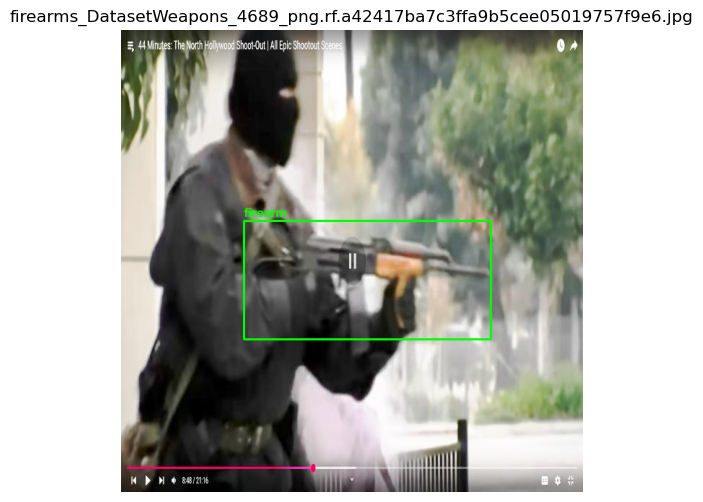

In [2]:
from pathlib import Path
import random
import cv2
import matplotlib.pyplot as plt

PROJECT_DIR = Path(
    r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion"
)
DATASET_DIR = PROJECT_DIR / "datasets" / "combined_yolo"

CLASS_NAMES = ["animal", "person", "firearm"]
IMAGE_DIR = DATASET_DIR / "images" / "train"
LABEL_DIR = DATASET_DIR / "labels" / "train"

images = [
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    and (LABEL_DIR / f"{p.stem}.txt").is_file()
]

if not images:
    raise RuntimeError("No labeled training images found.")

image_path = random.choice(images)
image = cv2.imread(str(image_path))

if image is None:
    raise RuntimeError(f"Cannot read image: {image_path.name}")

# Resize for visualization to limit memory use.
image = cv2.resize(image, (640, 640))
height, width = image.shape[:2]

for line in (LABEL_DIR / f"{image_path.stem}.txt").read_text().splitlines():
    parts = line.split()
    if len(parts) != 5:
        continue

    cls, x, y, w, h = map(float, parts)
    cls = int(cls)

    if cls not in range(len(CLASS_NAMES)):
        continue

    x1 = int((x - w / 2) * width)
    y1 = int((y - h / 2) * height)
    x2 = int((x + w / 2) * width)
    y2 = int((y + h / 2) * height)

    cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(
        image, CLASS_NAMES[cls], (max(0, x1), max(20, y1 - 5)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2
    )

plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title(image_path.name)
plt.axis("off")
plt.show()

In [5]:
from pathlib import Path

BASE_DIR = Path(r"C:\Users\Bilal\Desktop\Border intrusion")

matches = list(BASE_DIR.rglob("ena24.json"))

if matches:
    for file in matches:
        print("Found:", file)
        print("Size:", round(file.stat().st_size / (1024 * 1024), 2), "MB")
else:
    print("Not found under Border intrusion.")
    print("Please check the exact folder containing ena24.json.")

Found: C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion\datasets\raw\ena24\ena24.json
Size: 3.6 MB


In [7]:
from pathlib import Path
import json

BASE_DIR = Path(r"C:\Users\Bilal\Desktop\Border intrusion")

matches = list(BASE_DIR.rglob("ena24.json"))

if not matches:
    raise FileNotFoundError(
        "ena24.json not found. Check its location in File Explorer."
    )

JSON_PATH = matches[0]
print("Using:", JSON_PATH)
print("Size:", round(JSON_PATH.stat().st_size / (1024 * 1024), 2), "MB")

with JSON_PATH.open("r", encoding="utf-8") as f:
    data = json.load(f)

print("\nJSON type:", type(data).__name__)

if isinstance(data, dict):
    print("Top-level keys:", list(data.keys()))

    for key, value in data.items():
        if isinstance(value, list):
            print(f"\n{key}: {len(value)} items")
            if value:
                print("First item:", str(value[0])[:1000])
        elif isinstance(value, dict):
            print(f"\n{key}: dictionary with {len(value)} keys")
            print("Example:", str(value)[:500])
        else:
            print(f"\n{key}: {str(value)[:300]}")

elif isinstance(data, list):
    print("Number of records:", len(data))
    if data:
        print("First record:", str(data[0])[:1500])

Using: C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion\datasets\raw\ena24\ena24.json
Size: 3.6 MB

JSON type: dict
Top-level keys: ['images', 'annotations', 'categories', 'info']

images: 9676 items
First item: {'id': '1', 'file_name': '1.jpg', 'width': 1920, 'height': 1080}

annotations: 11596 items
First item: {'id': 'd8e94bd2-1df9-11ea-8572-5cf370671a19', 'image_id': '1', 'category_id': 0, 'bbox': [5.47008, 974.4170399999999, 162.279168, 72.97300800000001]}

categories: 23 items
First item: {'name': 'Bird', 'id': 0}

info: dictionary with 5 keys
Example: {'year': 2016, 'version': 1, 'description': '', 'secondary_contributor': 'Converted to COCO .json by Vardhan Duvvuri', 'contributor': 'University of Missouri'}


In [8]:
import json
from pathlib import Path
from collections import Counter

JSON_PATH = Path(
    r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion\datasets\raw\ena24\ena24.json"
)

with open(JSON_PATH, "r", encoding="utf-8") as f:
    data = json.load(f)

category_names = {
    category["id"]: category["name"]
    for category in data["categories"]
}

counts = Counter(
    annotation["category_id"]
    for annotation in data["annotations"]
)

print("Animal categories and annotation counts:\n")

for category_id, name in sorted(category_names.items()):
    print(f"{category_id:>3} | {name:<25} | {counts[category_id]} boxes")

print("\nTotal images:", len(data["images"]))
print("Total annotations:", len(data["annotations"]))

Animal categories and annotation counts:

  0 | Bird                      | 225 boxes
  1 | Eastern Gray Squirrel     | 319 boxes
  2 | Eastern Chipmunk          | 311 boxes
  3 | Woodchuck                 | 206 boxes
  4 | Wild Turkey               | 427 boxes
  5 | White_Tailed_Deer         | 381 boxes
  6 | Virginia Opossum          | 725 boxes
  7 | Eastern Cottontail        | 340 boxes
  8 | Human                     | 1161 boxes
  9 | Vehicle                   | 295 boxes
 10 | Striped Skunk             | 297 boxes
 11 | Red Fox                   | 413 boxes
 12 | Eastern Fox Squirrel      | 343 boxes
 13 | Northern Raccoon          | 292 boxes
 14 | Grey Fox                  | 438 boxes
 15 | Horse                     | 495 boxes
 16 | Dog                       | 774 boxes
 17 | American Crow             | 1278 boxes
 18 | Chicken                   | 749 boxes
 19 | Domestic Cat              | 491 boxes
 20 | Coyote                    | 344 boxes
 21 | Bobcat                    

In [9]:
import json
import shutil
from pathlib import Path
from collections import defaultdict

PROJECT_DIR = Path(
    r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion"
)

JSON_PATH = PROJECT_DIR / "datasets" / "raw" / "ena24" / "ena24.json"
ANIMAL_IMAGE_DIR = PROJECT_DIR / "datasets" / "extracted" / "ena24" / "ena24"
DATASET_DIR = PROJECT_DIR / "datasets" / "combined_yolo"

# Keep the original train/validation ratio approximately 95:5.
VAL_RATIO = 0.05

with JSON_PATH.open("r", encoding="utf-8") as f:
    data = json.load(f)

images_by_id = {str(img["id"]): img for img in data["images"]}
annotations_by_image = defaultdict(list)

for ann in data["annotations"]:
    annotations_by_image[str(ann["image_id"])].append(ann)

print("JSON images:", len(images_by_id))
print("JSON annotations:", len(data["annotations"]))
print("Animal image directory exists:", ANIMAL_IMAGE_DIR.is_dir())

if not ANIMAL_IMAGE_DIR.is_dir():
    raise FileNotFoundError(f"Animal image folder not found: {ANIMAL_IMAGE_DIR}")

# Reproducible assignment based on image ID.
def goes_to_val(image_id):
    try:
        return int(image_id) % 20 == 0
    except ValueError:
        return sum(map(ord, image_id)) % 20 == 0

added_images = 0
missing_images = []
invalid_boxes = 0

for image_id, image_info in images_by_id.items():
    file_name = Path(image_info["file_name"]).name
    source_image = ANIMAL_IMAGE_DIR / file_name

    if not source_image.is_file():
        missing_images.append(file_name)
        continue

    split = "val" if goes_to_val(image_id) else "train"
    image_out_dir = DATASET_DIR / "images" / split
    label_out_dir = DATASET_DIR / "labels" / split

    image_out_dir.mkdir(parents=True, exist_ok=True)
    label_out_dir.mkdir(parents=True, exist_ok=True)

    # Unique names prevent collisions with existing datasets.
    output_name = f"ena24_{file_name}"
    output_image = image_out_dir / output_name
    output_label = label_out_dir / f"{Path(output_name).stem}.txt"

    label_lines = []

    img_w = float(image_info["width"])
    img_h = float(image_info["height"])

    for ann in annotations_by_image.get(image_id, []):
        bbox = ann.get("bbox", [])

        if len(bbox) != 4 or img_w <= 0 or img_h <= 0:
            invalid_boxes += 1
            continue

        x, y, w, h = map(float, bbox)

        if w <= 0 or h <= 0:
            invalid_boxes += 1
            continue

        # COCO bbox: top-left x, top-left y, width, height.
        # YOLO bbox: normalized center x, center y, width, height.
        cx = (x + w / 2) / img_w
        cy = (y + h / 2) / img_h
        nw = w / img_w
        nh = h / img_h

        # Discard boxes outside image bounds rather than silently clipping.
        if not (
            0 <= cx <= 1 and 0 <= cy <= 1
            and 0 < nw <= 1 and 0 < nh <= 1
            and x >= 0 and y >= 0
            and x + w <= img_w and y + h <= img_h
        ):
            invalid_boxes += 1
            continue

        label_lines.append(
            f"0 {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}"
        )

    # Only add images that have at least one valid animal box.
    if not label_lines:
        continue

    # Do not overwrite a previously added image.
    if output_image.exists() or output_label.exists():
        print("Skipping existing:", output_name)
        continue

    shutil.copy2(source_image, output_image)
    output_label.write_text("\n".join(label_lines) + "\n", encoding="utf-8")
    added_images += 1

print("\nENA24 conversion complete.")
print("Animal images added:", added_images)
print("Missing source images:", len(missing_images))
print("Invalid boxes skipped:", invalid_boxes)
print("Output dataset:", DATASET_DIR)

if missing_images:
    print("Missing examples:", missing_images[:10])

JSON images: 9676
JSON annotations: 11596
Animal image directory exists: True

ENA24 conversion complete.
Animal images added: 8755
Missing source images: 887
Invalid boxes skipped: 42
Output dataset: C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion\datasets\combined_yolo
Missing examples: ['2672.jpg', '2673.jpg', '2675.jpg', '2679.jpg', '2681.jpg', '2682.jpg', '2688.jpg', '2689.jpg', '2690.jpg', '2691.jpg']


In [10]:
from pathlib import Path
import yaml

PROJECT_DIR = Path(
    r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion"
)
DATASET_DIR = PROJECT_DIR / "datasets" / "combined_yolo"

data_yaml = {
    "path": str(DATASET_DIR),
    "train": "images/train",
    "val": "images/val",
    "names": {
        0: "animal",
        1: "person",
        2: "firearm",
    },
    "nc": 3,
}

yaml_path = DATASET_DIR / "data.yaml"

with yaml_path.open("w", encoding="utf-8") as f:
    yaml.safe_dump(data_yaml, f, sort_keys=False)

print("Updated:", yaml_path)

for split in ["train", "val"]:
    image_dir = DATASET_DIR / "images" / split
    label_dir = DATASET_DIR / "labels" / split

    images = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in
        {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ]
    labels = list(label_dir.glob("*.txt"))

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Label files:", len(labels))

print("\nClasses:", data_yaml["names"])

Updated: C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion\datasets\combined_yolo\data.yaml

TRAIN
Images: 39939
Label files: 39939

VAL
Images: 2136
Label files: 2136

Classes: {0: 'animal', 1: 'person', 2: 'firearm'}


In [11]:
from pathlib import Path
from collections import Counter

PROJECT_DIR = Path(
    r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion"
)
DATASET_DIR = PROJECT_DIR / "datasets" / "combined_yolo"

CLASS_NAMES = {0: "animal", 1: "person", 2: "firearm"}
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for split in ["train", "val"]:
    image_dir = DATASET_DIR / "images" / split
    label_dir = DATASET_DIR / "labels" / split

    images = {
        p.stem for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    }
    labels = {p.stem: p for p in label_dir.glob("*.txt")}

    counts = Counter()
    invalid = []
    missing_labels = images - labels.keys()
    orphan_labels = labels.keys() - images

    for stem in images & labels.keys():
        for line_no, line in enumerate(
            labels[stem].read_text(encoding="utf-8").splitlines(), start=1
        ):
            parts = line.split()

            try:
                if len(parts) != 5:
                    raise ValueError("Expected 5 values")

                cls_float = float(parts[0])
                coords = list(map(float, parts[1:]))

                if not cls_float.is_integer():
                    raise ValueError("Class ID must be an integer")

                cls = int(cls_float)
                if cls not in CLASS_NAMES:
                    raise ValueError(f"Unexpected class ID: {cls}")

                x, y, w, h = coords
                if not all(0 <= v <= 1 for v in coords):
                    raise ValueError("Coordinate outside [0, 1]")
                if w <= 0 or h <= 0:
                    raise ValueError("Width/height must be positive")

                counts[cls] += 1

            except (ValueError, IndexError) as exc:
                invalid.append((labels[stem].name, line_no, str(exc)))

    print(f"\n--- {split.upper()} ---")
    print("Images:", len(images))
    print("Label files:", len(labels))
    print("Images without label files:", len(missing_labels))
    print("Labels without matching images:", len(orphan_labels))
    print("Invalid annotation lines:", len(invalid))
    print("Bounding boxes:", {
        CLASS_NAMES[c]: counts[c] for c in CLASS_NAMES
    })

    if invalid:
        print("Examples:", invalid[:5])

print("\nIntegrity check complete.")


--- TRAIN ---
Images: 39939
Label files: 39939
Images without label files: 0
Labels without matching images: 0
Invalid annotation lines: 0
Bounding boxes: {'animal': 17141, 'person': 78590, 'firearm': 22387}

--- VAL ---
Images: 2136
Label files: 2136
Images without label files: 0
Labels without matching images: 0
Invalid annotation lines: 0
Bounding boxes: {'animal': 599, 'person': 10017, 'firearm': 648}

Integrity check complete.


In [1]:
import sys
import os
import torch
import ultralytics

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)

try:
    import psutil
    mem = psutil.virtual_memory()
    print(f"RAM total: {mem.total / (1024**3):.1f} GB")
    print(f"RAM available: {mem.available / (1024**3):.1f} GB")
except ImportError:
    print("Install psutil if needed: %pip install psutil")

print("CPU threads:", os.cpu_count())
print("CUDA available:", torch.cuda.is_available())

# Test a tiny CPU tensor operation.
x = torch.rand(1, 3, 64, 64)
conv = torch.nn.Conv2d(3, 8, 3)
y = conv(x)
print("PyTorch CPU test passed:", tuple(y.shape))

Python: 3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]
PyTorch: 2.14.1+cpu
Ultralytics: 8.4.183
RAM total: 15.7 GB
RAM available: 1.7 GB
CPU threads: 16
CUDA available: False
PyTorch CPU test passed: (1, 8, 62, 62)


In [22]:
import os
import sys
import psutil
import torch
import ultralytics
from pathlib import Path
from ultralytics import YOLO

PROJECT_DIR = Path(r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion")
DATASET_DIR = PROJECT_DIR / "datasets" / "combined_yolo"
SMALL_DIR = PROJECT_DIR / "datasets" / "cpu_smoke_test"
RUNS_DIR = PROJECT_DIR / "runs" / "detect"

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print(f"Available RAM: {psutil.virtual_memory().available / (1024**3):.2f} GB")
print("CUDA available:", torch.cuda.is_available())

Python: 3.13.5
PyTorch: 2.14.1+cpu
Ultralytics: 8.4.183
Available RAM: 2.96 GB
CUDA available: False


In [23]:
print("Combined dataset exists:", DATASET_DIR.exists())
print("Smoke-test dataset exists:", SMALL_DIR.exists())

print("\nSmoke-test data.yaml:")
print((SMALL_DIR / "data.yaml").read_text() if (SMALL_DIR / "data.yaml").exists()
      else "MISSING")

for split in ["train", "val"]:
    images = SMALL_DIR / "images" / split
    labels = SMALL_DIR / "labels" / split

    print(f"\n{split.upper()}")
    print("Images:", len(list(images.glob("*"))) if images.exists() else "MISSING")
    print("Labels:", len(list(labels.glob("*.txt"))) if labels.exists() else "MISSING")

Combined dataset exists: True
Smoke-test dataset exists: True

Smoke-test data.yaml:
path: C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion\datasets\cpu_smoke_test
train: images/train
val: images/val
names:
  0: animal
  1: person
  2: firearm
nc: 3


TRAIN
Images: 300
Labels: 300

VAL
Images: 60
Labels: 60


In [2]:
import gc
import torch

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

import psutil
print(f"Available RAM: {psutil.virtual_memory().available / 1024**3:.2f} GB")

Available RAM: 4.49 GB


In [4]:
from pathlib import Path
from ultralytics import YOLO

PROJECT_DIR = Path(r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion")
DATASET_DIR = PROJECT_DIR / "datasets" / "combined_yolo"
RUNS_DIR = PROJECT_DIR / "runs" / "detect"

print("Dataset YAML exists:", (DATASET_DIR / "data.yaml").exists())
print("Output folder:", RUNS_DIR)

Dataset YAML exists: True
Output folder: C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion\runs\detect


In [3]:
import sys
import torch
import ultralytics

print("Python:", sys.version)
print("Executable:", sys.executable)
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)

Python: 3.11.17 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:16:54) [MSC v.1942 64 bit (AMD64)]
Executable: c:\Users\Bilal\anaconda3\envs\forest-yolo\python.exe
PyTorch: 2.14.1+cpu
Ultralytics: 8.4.183


In [4]:
import sys
from pathlib import Path
import torch
import ultralytics

PROJECT_DIR = Path(r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion")
DATASET_DIR = PROJECT_DIR / "datasets" / "combined_yolo"
DATA_YAML = DATASET_DIR / "data.yaml"
RUNS_DIR = PROJECT_DIR / "runs" / "detect"

print("Python:", sys.version.split()[0])
print("Environment:", sys.executable)
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("Dataset YAML exists:", DATA_YAML.exists())
print("Training images:", len(list((DATASET_DIR / "images" / "train").glob("*"))))
print("Validation images:", len(list((DATASET_DIR / "images" / "val").glob("*"))))

Python: 3.11.17
Environment: c:\Users\Bilal\anaconda3\envs\forest-yolo\python.exe
PyTorch: 2.14.1+cpu
Ultralytics: 8.4.183
Dataset YAML exists: True
Training images: 39939
Validation images: 2136


In [5]:
from pathlib import Path
from ultralytics import YOLO

PROJECT_DIR = Path(r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion")
DATA_YAML = PROJECT_DIR / "datasets" / "combined_yolo" / "data.yaml"
RUNS_DIR = PROJECT_DIR / "runs" / "detect"

assert DATA_YAML.exists(), f"Dataset not found: {DATA_YAML}"

model = YOLO("yolov8n.pt")

model.train(
    data=str(DATA_YAML),
    epochs=1,
    imgsz=416,
    batch=2,
    device="cpu",
    workers=0,
    project=str(RUNS_DIR),
    name="forest_cpu_test_py311",
    exist_ok=True,
    save=True,
    plots=False,
    cache=False,
    patience=5,
)

Ultralytics 8.4.183  Python-3.11.17 torch-2.14.1+cpu CPU (13th Gen Intel Core i7-13620H)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion\datasets\combined_yolo\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, 

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x0000028E5A0F7B50>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          

In [9]:
from pathlib import Path
from ultralytics import YOLO

PROJECT_DIR = Path(r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion")

DATA_YAML = PROJECT_DIR / "datasets" / "combined_yolo" / "data.yaml"
WEIGHTS = PROJECT_DIR / "runs" / "detect" / "forest_cpu_test_py311" / "weights" / "best.pt"

assert DATA_YAML.exists(), f"Dataset config missing: {DATA_YAML}"
assert WEIGHTS.exists(), f"Model weights missing: {WEIGHTS}"

print("Dataset:", DATA_YAML)
print("Weights:", WEIGHTS)

model = YOLO(str(WEIGHTS))

model.train(
    data=str(DATA_YAML),
    epochs=5,
    imgsz=416,
    batch=2,
    device="cpu",
    workers=0,
    project=str(PROJECT_DIR / "runs" / "detect"),
    name="forest_finetune_5",
    exist_ok=True,
    cache=False,
    plots=False
)

Dataset: C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion\datasets\combined_yolo\data.yaml
Weights: C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion\runs\detect\forest_cpu_test_py311\weights\best.pt
Ultralytics 8.4.183  Python-3.11.17 torch-2.14.1+cpu CPU (13th Gen Intel Core i7-13620H)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion\datasets\combined_yolo\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, 

KeyboardInterrupt: 

In [1]:
from pathlib import Path
from ultralytics import YOLO

PROJECT_DIR = Path(r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion")
WEIGHTS = PROJECT_DIR / "runs" / "detect" / "forest_cpu_test_py311" / "weights" / "best.pt"

assert WEIGHTS.exists(), f"Weights not found: {WEIGHTS}"

model = YOLO(str(WEIGHTS))
print("Classes:", model.names)

model.predict(
    source=0,
    imgsz=416,
    conf=0.25,
    device="cpu",
    show=True,
    save=False
)

Classes: {0: 'animal', 1: 'person', 2: 'firearm'}

1/1: 0... Success  (inf frames of shape 640x480 at 30.00 FPS)

WARNING 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

0: 320x416 (no detections), 599.4ms
0: 320x416 (no detections), 376.6ms
0: 320x416 (no detections), 692.5ms
0: 320x416 (no detections), 90.0ms
0: 320x416 (no detections), 38.9ms
WARNING Waiting for stream 0
0: 320x416 (no detections), 43.1ms
0: 320x416 (no detections), 18.3ms
WARNING Waiting for stream 0
0: 320x416 (no detections), 21.4ms
WARNING 

KeyboardInterrupt: 

In [5]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

model.train(
    data=str(DATASET_DIR / "data.yaml"),
    epochs=1,
    imgsz=416,
    batch=2,
    device="cpu",
    workers=0,
    project=str(RUNS_DIR),
    name="forest_cpu_test",
    exist_ok=True,
    save=True,
    plots=False,
    cache=False,
    patience=5,
)

Ultralytics 8.4.183  Python-3.13.5 torch-2.14.1+cpu CPU (13th Gen Intel Core i7-13620H)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion\datasets\combined_yolo\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, n

: 

In [1]:
from pathlib import Path
from ultralytics import YOLO
import yaml

PROJECT_DIR = Path(
    r"C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion"
)
DATASET_DIR = PROJECT_DIR / "datasets" / "combined_yolo"
SMALL_DIR = PROJECT_DIR / "datasets" / "cpu_smoke_test"

# Build a small dataset using symlinks where possible, copies otherwise.
# Labels and images stay paired by filename.
for split, limit in [("train", 300), ("val", 60)]:
    img_src = DATASET_DIR / "images" / split
    lbl_src = DATASET_DIR / "labels" / split

    img_dst = SMALL_DIR / "images" / split
    lbl_dst = SMALL_DIR / "labels" / split
    img_dst.mkdir(parents=True, exist_ok=True)
    lbl_dst.mkdir(parents=True, exist_ok=True)

    images = sorted(
        p for p in img_src.iterdir()
        if p.is_file() and (lbl_src / f"{p.stem}.txt").is_file()
    )[:limit]

    for src in images:
        dst_img = img_dst / src.name
        dst_lbl = lbl_dst / f"{src.stem}.txt"

        if not dst_img.exists():
            try:
                dst_img.symlink_to(src)
            except OSError:
                import shutil
                shutil.copy2(src, dst_img)

        source_label = lbl_src / f"{src.stem}.txt"
        if not dst_lbl.exists():
            try:
                dst_lbl.symlink_to(source_label)
            except OSError:
                import shutil
                shutil.copy2(source_label, dst_lbl)

    print(f"{split}: prepared {len(images)} images")

small_yaml = {
    "path": str(SMALL_DIR),
    "train": "images/train",
    "val": "images/val",
    "names": {0: "animal", 1: "person", 2: "firearm"},
    "nc": 3,
}
with (SMALL_DIR / "data.yaml").open("w", encoding="utf-8") as f:
    yaml.safe_dump(small_yaml, f, sort_keys=False)

model = YOLO("yolov8n.pt")
model.train(
    data=str(SMALL_DIR / "data.yaml"),
    epochs=1,
    imgsz=320,
    batch=2,
    device="cpu",
    workers=0,
    cache=False,
    plots=False,
    save=True,
    project=str(PROJECT_DIR / "runs" / "detect"),
    name="forest_cpu_smoke_test",
    exist_ok=True,
)

train: prepared 300 images
val: prepared 60 images
Ultralytics 8.4.183  Python-3.13.5 torch-2.14.1+cpu CPU (13th Gen Intel Core i7-13620H)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Bilal\Desktop\Border intrusion\forest-intrusion\datasets\cpu_smoke_test\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8

: 

In [10]:
def show_samples(split="train", count=6):
    image_dir = DATASET_DIR / "images" / split
    label_dir = DATASET_DIR / "labels" / split

    images = [p for p in image_dir.iterdir()
              if p.suffix.lower() in IMAGE_EXTS]

    if not images:
        print("No images found.")
        return

    for image_path in random.sample(images, min(count, len(images))):
        image = cv2.imread(str(image_path))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        height, width = image.shape[:2]
        label_path = label_dir / f"{image_path.stem}.txt"

        if label_path.exists():
            for line in label_path.read_text().splitlines():
                parts = line.split()
                if len(parts) != 5:
                    continue

                cls, x, y, w, h = map(float, parts)
                x1 = int((x - w / 2) * width)
                y1 = int((y - h / 2) * height)
                x2 = int((x + w / 2) * width)
                y2 = int((y + h / 2) * height)

                cv2.rectangle(image, (x1, y1), (x2, y2), (255, 80, 30), 2)
                cv2.putText(
                    image, CLASS_NAMES[int(cls)], (x1, max(20, y1 - 5)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 80, 30), 2
                )

        plt.figure(figsize=(8, 5))
        plt.imshow(image)
        plt.title(image_path.name)
        plt.axis("off")
        plt.show()

show_samples()

FileNotFoundError: [WinError 3] The system cannot find the path specified: '\\content\\forest-intrusion\\datasets\\raw\\images\\train'

In [ ]:
import torch

if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU available. In Colab, select Runtime > Change runtime type "
        "> T4 GPU, then rerun Cell 2."
    )

print("Training GPU:", torch.cuda.get_device_name(0))

model = YOLO("yolov8n.pt")

results = model.train(
    data=str(DATA_YAML),
    epochs=20,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    patience=5,
    seed=SEED,
    project=str(RUNS_DIR),
    name="forest_v1",
    exist_ok=True,
    plots=True,
    save=True
)

BEST_MODEL = RUNS_DIR / "forest_v1" / "weights" / "best.pt"

if not BEST_MODEL.exists():
    raise FileNotFoundError(f"Trained checkpoint not found: {BEST_MODEL}")

print("Best checkpoint:", BEST_MODEL)

In [ ]:
model = YOLO(str(BEST_MODEL))

metrics = model.val(
    data=str(DATA_YAML),
    split="test" if "test" in data_config else "val",
    imgsz=640,
    batch=4,
    device=0,
    plots=True
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

In [ ]:
from google.colab import files

uploaded_media = files.upload()

media_files = [
    name for name in uploaded_media
    if Path(name).suffix.lower() in IMAGE_EXTS | {".mp4", ".avi", ".mov", ".mkv"}
]

if not media_files:
    raise ValueError("Upload a supported image or video.")

MEDIA_PATH = media_files[0]

model = YOLO(str(BEST_MODEL))

predictions = model.predict(
    source=MEDIA_PATH,
    conf=0.35,
    imgsz=640,
    save=True,
    project=str(RUNS_DIR),
    name="forest_test",
    exist_ok=True
)

print("Annotated output saved under:", RUNS_DIR / "forest_test")

In [ ]:
VIDEO_PATH = MEDIA_PATH

if Path(VIDEO_PATH).suffix.lower() not in {".mp4", ".avi", ".mov", ".mkv"}:
    raise ValueError("Upload a video before running this cell.")

model = YOLO(str(BEST_MODEL))

track_results = model.track(
    source=VIDEO_PATH,
    tracker="bytetrack.yaml",
    conf=0.35,
    imgsz=640,
    persist=True,
    save=True,
    project=str(RUNS_DIR),
    name="forest_tracking",
    exist_ok=True
)

print("Tracked video output:", RUNS_DIR / "forest_tracking")

In [ ]:
EXPORT_DIR = PROJECT_DIR / "models"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

local_checkpoint = EXPORT_DIR / "best.pt"
shutil.copy2(BEST_MODEL, local_checkpoint)

print("Checkpoint ready:", local_checkpoint)

from google.colab import files
files.download(str(local_checkpoint))